In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch
from matplotlib.gridspec import GridSpec

import seaborn as sns
import os
import datetime
import pickle

from astropy.timeseries import LombScargle
from astropy.stats.circstats import circmean, circvar
from scipy.signal import hilbert

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import spectralanalysis
from src.dataproc import utils, ccutils
from src.visualize import cycleviz

## Supporting function

## Data

In [5]:
save_flag = False

In [6]:
FEATURE_TYPE = 'plv'  # 'plv', 'pib'
DATA_RANGE = 'interval'  # 'total' or 'interval'

implantinfo_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
featdf_path = 'data/processed/ecogfeatures/plv_postproc/%s_trigger-Scheduled.csv'
lsdf_path = 'data/processed/lscycles/plv_postproc_interval/%s.csv'
stimname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'

implantdf = pd.read_csv(implantinfo_path)   # date when RNS was implanted

In [7]:
patient_id = 'NPE0095'
feature_list = ['Ch_1-Ch_2_alpha', 'Ch_3-Ch_4_alpha']

# implant date
implant_date = datetime.datetime.fromisoformat(implantdf.loc[implantdf['npe_code']==patient_id]['implant_date'].item())

# longitudinal outcomes
lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

### PLV data
featdf = pd.read_csv(featdf_path % (patient_id))
featdf['Round_local_hour'] = featdf['Round local timestamp'].apply(lambda x: datetime.datetime.fromisoformat(x).hour).values

# time from implantation
utils.tfromstart_days(featdf, start_date=implant_date)  # time from the date of implantation
ccutils.round_half_year_days(featdf)  # 6 month bin to which a sample belongs

## stimulation data
stimdf = pd.read_csv(stimname_format %(patient_id))
stimdf['Local_hour'] = stimdf['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
stimdf['npe_code'] = patient_id

# time from implantation
utils.tfromstart_days(stimdf, datecol='Region start time', start_date=implant_date)
ccutils.round_half_year_days(stimdf)

# lomb scargle
lsdf_dict = {}
lsdf_dict[patient_id] = pd.read_csv(lsdf_path % (patient_id))

print('')

### A: Schematics of cycles

In [8]:
sunmarker = '$\u2600$'
moonmarker = '$\u263D$'

timevals = np.linspace(0, 6*np.pi, num=50)

left_hippo = 0.5 * np.sin(timevals) + 3.5
right_hippo = 0.5 * -1 * np.sin(timevals) + 2.25
stim_cycle = 0.5 * np.cos(timevals) + 1

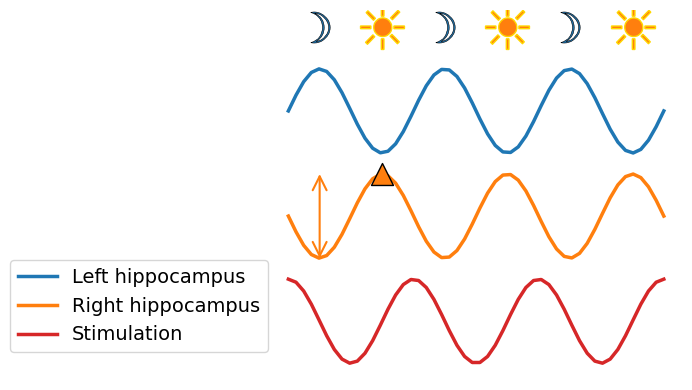

In [9]:
fig, ax = plt.subplots(1,1, figsize=(7,4))

# circadian lines
ax.plot(timevals, left_hippo, color='tab:blue', linewidth=2.5, label='Left hippocampus')
ax.plot(timevals, right_hippo, color='tab:orange', linewidth=2.5, label='Right hippocampus')
ax.plot(timevals, stim_cycle, color='tab:red', linewidth=2.5, label='Stimulation')

# markers
ax.scatter(x=np.array([0, 2*np.pi, 4*np.pi]) + np.pi/2, y=4.5 * np.ones(3), s=500, marker=moonmarker, edgecolors='k', linewidth=0.4)
ax.scatter(x=np.array([0, 2*np.pi, 4*np.pi]) + 3*np.pi/2, y=4.5 * np.ones(3), s=1000, marker=sunmarker, edgecolors='gold')

# circadian markers
ax.scatter(x=3*np.pi/2, y=2.75, marker='^', s=250, color='tab:orange', edgecolor='k', zorder=3)
ax.annotate(
    "",  # No text required
    xytext=(np.pi/2, 1.75),  # Arrow START position (x, y)
    xy=(np.pi/2, 2.75),          # Arrow END position (x + dx, y + dy)
    arrowprops=dict(
        arrowstyle="<->, head_length=1, head_width=0.5",       # <-- KEY CHANGE: Draws heads on both ends
        color='tab:orange',
        linewidth=1.5,            # Use linewidth for thickness (like head_width does for ax.arrow)
        shrinkA=0,              # Ensures the arrow starts exactly at xytext
        shrinkB=0,               # Ensures the arrow ends exactly at xy
    )
)


# legend and aesthetics
ax.legend(fontsize=14, bbox_to_anchor=(0.02, 0.35))
ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

fig.tight_layout()

if save_flag:
    plt.savefig('output/circpaper_figures/fig01/cartoon_cycles.pdf', dpi=300)

plt.show()

### B: Circadian cycles from data

In [10]:
ls_days = 182  # 182,  365,  548,  730,  912, 1095, 1278 ...

## subset data based on days intervals
subfeatdf = featdf.loc[featdf['dur_halfyr']==ls_days].copy()
subfeatdf[feature_list] = ( subfeatdf[feature_list] - subfeatdf[feature_list].mean() ) / subfeatdf[feature_list].std() # z-score features

# read data
ymean = subfeatdf.groupby(by='Round_local_hour')[feature_list].median().reset_index()
yerr = subfeatdf.groupby(by='Round_local_hour')[feature_list].apply(lambda x: x.std() / np.sqrt(len(x)) ).reset_index()

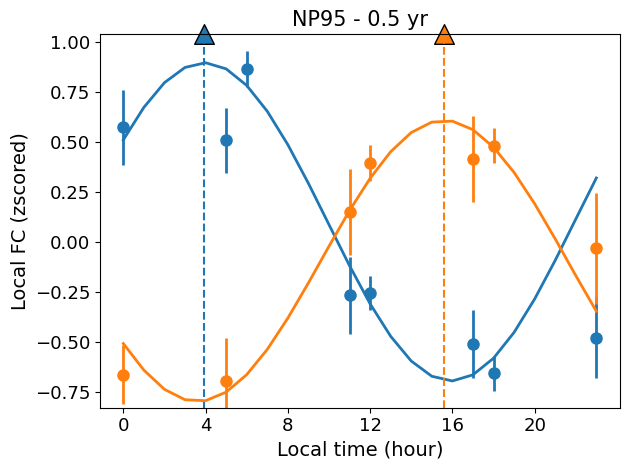

In [11]:
### combined plot for all timeseries

# plotting
fig, ax = plt.subplots(1, 1)

# FC-CC
left_peak_hour = cycleviz.LSpointplot(ax=ax, subfeatdf=subfeatdf, ymean=ymean, yerr=yerr, featname='Ch_1-Ch_2_alpha', 
                                      color='tab:blue', marker='^', leglabel='Left hemisphere')
right_peak_hour = cycleviz.LSpointplot(ax=ax, subfeatdf=subfeatdf, ymean=ymean, yerr=yerr, featname='Ch_3-Ch_4_alpha', 
                                       color='tab:orange', marker='^', leglabel='Right hemisphere')

# aesthetics
ax.set_xlabel('Local time (hour)', fontsize=14)
ax.set_ylabel('Local FC (zscored)', fontsize=14)
# ax.legend(fontsize=14, loc=1)

# ax_2.set_ylabel('# stimulations (norm.)', fontsize=14, color='tab:red')

ax.set_xticks(ticks=np.arange(24, step=4), labels=np.arange(24, step=4))
ax.tick_params(labelsize=13)
# ax_2.tick_params(labelsize=13, labelcolor='tab:red')

ax.set_title(f'{utils.format_patid(patient_id)} - {np.round(ls_days/365, 1)} yr', fontsize=15)

fig.tight_layout()

if save_flag:
    fig.savefig('output/circpaper_figures/fig01/LS_only_first6month.pdf', dpi=300)

plt.show()

### D: FC-CC and stimulation cycles over time

In [12]:
feature_list = lsdf_dict[patient_id]['feature'].to_list()
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']  # local FC, long-range FC, both FCs

subfeatdict = ccutils.get_subfeatdict(feature_list, band_list, edge_type_list)

print('Verify the number of features of each type in the dict:')
print([len(subfeatdict[keyval1][keyval2]) for keyval1 in subfeatdict.keys() 
       for keyval2 in subfeatdict[keyval1].keys()])

Verify the number of features of each type in the dict:
[2, 2, 2, 2, 8]


In [13]:
band_list = ['alpha']
edge_type_list = ['local']
mreg_id_vars = ['npecode', 'feat_days', 'baseline_seizure_rate', 'outcome_days', 'sz_red', 
                'auc', 'auc_interval', 'auc_converse', 'max_hour', 'sin_hour', 'cos_hour']
mreg_value_vars = ['amp_unnorm_local', 'peakhour_local']

# FC-CC features
npe95_featdf = ccutils.create_lgfcccfeat_dataframe(lsdf_dict, [patient_id], band_list, edge_type_list, subfeatdict)
npe95_featdf['yrs_from_implant'] = npe95_featdf['days_from_implant'].apply(lambda x: round(x / 365, 1))

In [14]:
## outcomes
npe95_outdf = lgpatcodesdf.loc[lgpatcodesdf['npe_code']==patient_id].copy()
npe95_outdf['yrs_from_implant'] = npe95_outdf['days_from_implant'].apply(lambda x: round(x / 365, 1))

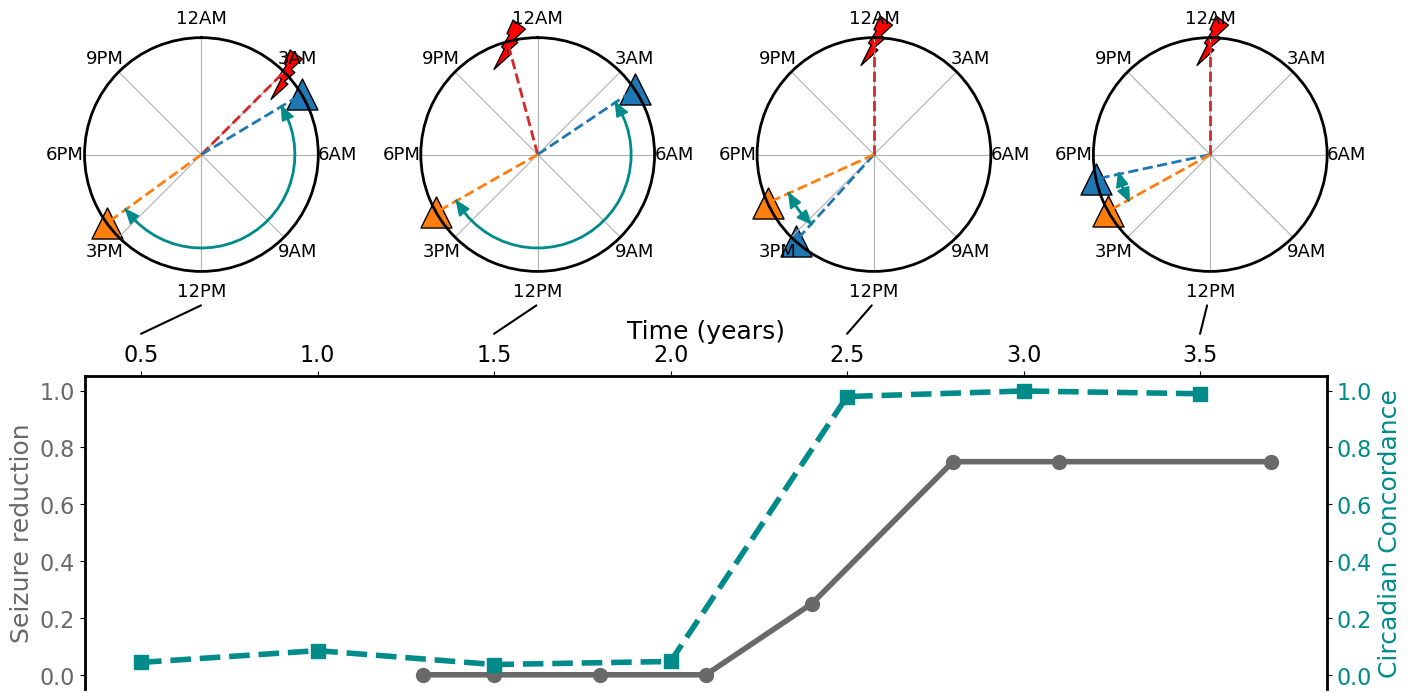

In [15]:
fig_ylim = [-0.05, 1.05]
peak_sync_color = 'darkcyan'
sz_red_color = 'dimgrey'

fig = plt.figure(figsize=(3.5*4, 3.5*2), layout="constrained") #
gs = GridSpec(2, 4, figure=fig) #

######################## polar data #########################

ls_days_list = [182,   548,  912, 1278]

ax_bottom1 = fig.add_subplot(gs[0, 0], projection='polar')
ax_bottom2 = fig.add_subplot(gs[0, 1], projection='polar')
ax_bottom3 = fig.add_subplot(gs[0, 2], projection='polar')
ax_bottom4 = fig.add_subplot(gs[0, 3], projection='polar')

# Plot data on bottom subplots (optional)
fax = [ax_bottom1, ax_bottom2, ax_bottom3, ax_bottom4]

for ii in range(len(ls_days_list)): 
    ls_days = ls_days_list[ii]

    ## subset data based on days intervals
    subfeatdf = featdf.loc[featdf['dur_halfyr']==ls_days].copy()
    subfeatdf[feature_list] = ( subfeatdf[feature_list] - subfeatdf[feature_list].mean() ) / subfeatdf[feature_list].std() # z-score features
    
    # read data
    ymean = subfeatdf.groupby(by='Round_local_hour')[feature_list].median().reset_index()
    yerr = subfeatdf.groupby(by='Round_local_hour')[feature_list].apply(lambda x: x.std() / np.sqrt(len(x)) ).reset_index()
    
    # stimulation data mean
    stimmean = stimdf.loc[stimdf['dur_halfyr']==ls_days].groupby(by='Local_hour')['Episode starts with RX'].mean().reset_index()
    stimmean.rename(columns={'Episode starts with RX':'stimcount'}, inplace=True)
    
    stimerr = stimdf.loc[stimdf['dur_halfyr']==ls_days].groupby(by='Local_hour')['Episode starts with RX'].apply(lambda x: x.std() / np.sqrt(len(x)) ).reset_index()
    stimerr.rename(columns={'Episode starts with RX':'stimcount'}, inplace=True)
    
    stimmean['stimcount_zs'] = ( stimmean['stimcount'] - stimmean['stimcount'].mean() ) / stimmean['stimcount'].std()
    
    # stimulation
    polar_stimmean = pd.concat((stimmean, stimmean.iloc[[0]]), axis=0, ignore_index=True)
    stim_max_hour = polar_stimmean.loc[polar_stimmean['stimcount_zs'].idxmax()]['Local_hour']
    
    # fax[ii].plot(np.pi/12 * polar_stimmean['Local_hour'], polar_stimmean['stimcount_zs'], color='tab:red', linewidth=2)
    fax[ii].axvline(x=np.pi/12 * stim_max_hour, linestyle='--', linewidth=2, color='tab:red')
    plot_rmin, plot_rmax = fax[ii].get_rmin(), fax[ii].get_rmax()
    fax[ii].scatter(np.pi/12 * stim_max_hour, plot_rmax, s=1500, c='red', marker=cycleviz.lightning_bolt(), 
                edgecolor='k', clip_on=False)
    fax[ii].set_rlim([plot_rmin, plot_rmax])
    
    # FC-CC
    peak_angle_12 = cycleviz.LSpointplot_polar(ax=fax[ii], subfeatdf=subfeatdf, ymean=ymean, yerr=yerr, featname='Ch_1-Ch_2_alpha', 
                               color='tab:blue', show_points=False, show_lsamp=False, marker='^', linewidth=2)
    peak_angle_34 = cycleviz.LSpointplot_polar(ax=fax[ii], subfeatdf=subfeatdf, ymean=ymean, yerr=yerr, featname='Ch_3-Ch_4_alpha', 
                               color='tab:orange', show_points=False, show_lsamp=False, marker='^', linewidth=2)

    cycleviz.arrow_arc_long(ax=fax[ii], start_angle=peak_angle_12, end_angle=peak_angle_34, 
                            arrow_radius=0.8*plot_rmax, color='darkcyan', linestyle='-')

    # aesthetics
    fax[ii].set_theta_zero_location("N")  # Set 0 at the top
    fax[ii].set_theta_direction(-1)      # Clockwise direction
    fax[ii].set_xticks(ticks=[0, np.pi/4, 2*np.pi/4, 3*np.pi/4, 
                         np.pi, 5*np.pi/4, 6*np.pi/4, 7*np.pi/4], 
                  labels=['12AM', '3AM', '6AM', '9AM', 
                          '12PM', '3PM', '6PM', '9PM'], fontsize=13)
    fax[ii].set_yticks([])
    fax[ii].spines['polar'].set_linewidth(2)
    
    # fax[ii].set_title(f'{np.round(ls_days/365,1)} yr', fontsize=14)


######################## longitudinal data #########################
ax_top = fig.add_subplot(gs[1, :])

#### patient 1
lns1 = ax_top.plot(npe95_outdf['yrs_from_implant'], npe95_outdf['sz_red'], '-o', 
                   linewidth=4, markersize=10, color=sz_red_color)
ax_top.set_ylim(fig_ylim)
ax_top.set_ylabel('Seizure reduction', fontsize=18, color=sz_red_color)
ax_top.tick_params(axis='y', labelsize=16, labelcolor=sz_red_color)

ax_top_2 = ax_top.twinx()
lns2 = ax_top_2.plot(npe95_featdf['yrs_from_implant'], npe95_featdf['peakhour_local'], '--s', 
                  linewidth=4, markersize=10, color=peak_sync_color)
ax_top_2.set_ylim(fig_ylim)
ax_top_2.set_ylabel('Circadian Concordance', fontsize=18, color=peak_sync_color)
ax_top_2.tick_params(axis='y', labelsize=16, labelcolor=peak_sync_color)

ax_top.set_xlabel('Time (years)', fontsize=18)
ax_top.xaxis.set_label_position('top')
ax_top.tick_params(axis='x', labelsize=16, bottom=False, top=True, labelbottom=False, labeltop=True)

ax_top.spines['top'].set_linewidth(2)
ax_top.spines['bottom'].set_visible(False)
ax_top_2.spines['bottom'].set_visible(False)
ax_top.spines['left'].set_linewidth(2)
ax_top.spines['right'].set_linewidth(2)


### add connections between panels and time

con1 = ConnectionPatch(xyA=(0.5, 1.2), coordsA=ax_top.transData, xyB=(0.67, 1.3), color="black", linestyle="-", linewidth=1.5, zorder=0)
con2 = ConnectionPatch(xyA=(1.5, 1.2), coordsA=ax_top.transData, xyB=(1.62, 1.3), color="black", linestyle="-", linewidth=1.5, zorder=0)
con3 = ConnectionPatch(xyA=(2.5, 1.2), coordsA=ax_top.transData, xyB=(2.57, 1.3), color="black", linestyle="-", linewidth=1.5, zorder=0)
con4 = ConnectionPatch(xyA=(3.5, 1.2), coordsA=ax_top.transData, xyB=(3.52, 1.3), color="black", linestyle="-", linewidth=1.5, zorder=0)

fig.add_artist(con1)
fig.add_artist(con2)
fig.add_artist(con3)
fig.add_artist(con4)

if save_flag:
    plt.savefig('output/circpaper_figures/fig01/longi_polar_combined.pdf', dpi=300)

plt.show()

### E: Kuramoto model

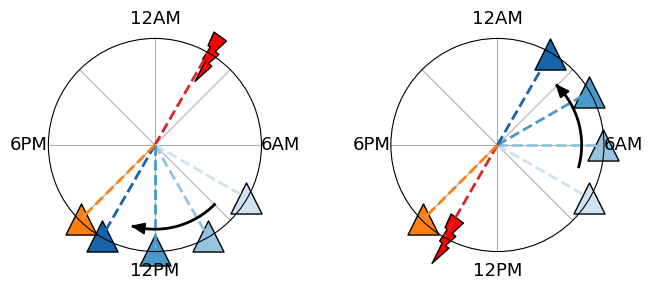

In [16]:
fccc_angles_list = np.pi / 12 * np.array([[8, 10, 12, 14, 15], [8, 6, 4, 2, 15]])
stim_angle = np.pi / 12 * np.array([2, 14])
arrow_start_end_list = np.pi / 12 * np.array([[9, 13], [7, 3]])
blues_list = sns.color_palette(palette='Blues', n_colors=4)

ncols = 2
nrows = 1
fig, ax = plt.subplots(nrows, ncols, figsize=(3.5*ncols, 3*nrows),
                       subplot_kw={'projection':'polar'})

fax = ax.flatten()

plot_rmin, plot_rmax = 0, 1

for ii in range(len(fccc_angles_list)): 
    fccc_angles = fccc_angles_list[ii]
    arstartend = arrow_start_end_list[ii]
    
    # stimulation    
    fax[ii].scatter(stim_angle[ii], plot_rmax, s=1500, color='red', marker=cycleviz.lightning_bolt(), edgecolor='k', clip_on=False)
    fax[ii].axvline(x=stim_angle[ii], linestyle='--', color='tab:red', linewidth=2)
    
    # FC-CC
    for fcn in range(len(fccc_angles[:-1])):
        fax[ii].scatter(fccc_angles[fcn], plot_rmax, color=blues_list[fcn], marker='^', s=500, edgecolor='k', clip_on=False)
        fax[ii].axvline(x=fccc_angles[fcn], linestyle='--', color=blues_list[fcn], linewidth=2)
    
    
    fax[ii].scatter(fccc_angles[-1], plot_rmax, color='tab:orange', marker='^', s=500, edgecolor='k', clip_on=False)
    fax[ii].axvline(x=fccc_angles[-1], linestyle='--', color='tab:orange', linewidth=2)

    # arrow
    fax[ii].plot(np.linspace(arstartend[0], arstartend[1], 30), 0.8*plot_rmax*np.ones(30), linewidth=2, 
                 linestyle='-', color='k')
    fax[ii].arrow(x=arstartend[1], y=0.8*plot_rmax, dx=np.sign(np.diff(arstartend)[0]) * np.pi/360, dy=0, head_starts_at_zero=False,
                  length_includes_head=True, head_width=0.1, color='k')

    # aesthetics
    # fax[ii].set_rlim([plot_rmin, plot_rmax + 0.5])   # manually increased the radius a little bit so that the markers are not clipped
    
    fax[ii].set_theta_zero_location("N")  # Set 0 at the top
    fax[ii].set_theta_direction(-1)      # Clockwise direction

    fax[ii].set_xticks(ticks=[0, np.pi/4, 2*np.pi/4, 3*np.pi/4, 
                         np.pi, 5*np.pi/4, 6*np.pi/4, 7*np.pi/4], 
                  labels=['12AM', '', '6AM', '', '12PM', '', '6PM', ''], fontsize=13)    
    fax[ii].set_yticks([])
    
    fax[ii].set_title('', fontsize=14)


plt.subplots_adjust(left=0.05, right=0.95, bottom=0.1, top=0.95, wspace=0.1)
fig.tight_layout()

if save_flag:
    plt.savefig('output/circpaper_figures/fig01/kuramoto_cartoon.pdf', dpi=300)

plt.show()